<a href="https://colab.research.google.com/github/Fata-Haidar/PCVK_Ganjil_2026/blob/main/Pertemuan_5/Week5_07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
# ===== SEL IDENTITAS - JANGAN DIHAPUS, HARUS SEL PERTAMA =====
import sys, platform, hashlib, datetime, zoneinfo

NAMA = 'Fata Haidar Aly'
NIM = '244107020108'  # ganti dengan NIM Anda

N = int(NIM[-3:])

PARAM = {
    'bins': 2 ** ((N % 4) + 3),
    'clip': round(1.0 + (N % 5) * 0.5, 1),
    'tile': (N % 4) + 2,
    'L': 2 ** ((N % 3) + 1),
}

waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))

print('NAMA :', NAMA)
print('NIM :', NIM, '| N =', N)

for k, v in PARAM.items():
    print('%-6s :' % k, v)

print('WAKTU :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('SISTEM :', sys.version.split()[0], platform.platform())

kunci = NIM + '|' + waktu.strftime('%Y-%m-%d')
print('TOKEN :', hashlib.sha256(kunci.encode()).hexdigest()[:16])

NAMA : Fata Haidar Aly
NIM : 244107020108 | N = 108
bins   : 8
clip   : 2.5
tile   : 2
L      : 2
WAKTU : 2026-09-30 18:49:50 WIB
SISTEM : 3.13.15 Linux-6.6.122+-x86_64-with-glibc2.39
TOKEN : 6aae8643af3aaf0d


**E-1 PERCOBAAN HISTOGRAM**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import cv2 as cv
from google.colab.patches import cv2_imshow
from skimage import io
import matplotlib.pyplot as plt
import numpy as np
import math
import os
import glob

<BarContainer object of 256 artists>

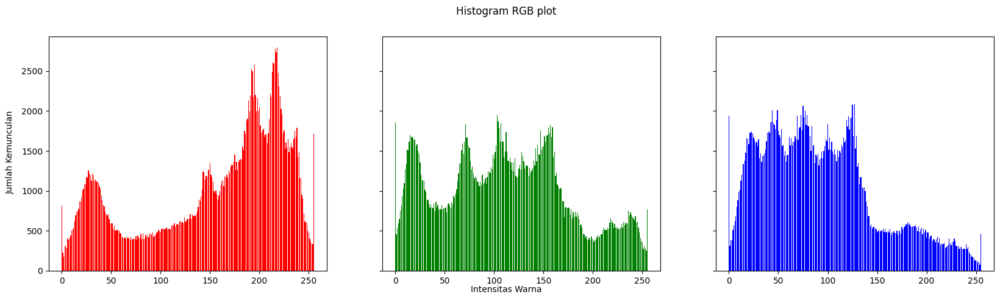

In [3]:
# membuat histogram image (manual)
img = cv.imread('/content/drive/MyDrive/PCVK/lena.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img)
names = np.arange(256)

red = [0]*256
green = [0]*256
blue = [0]*256

for y in range(0, height):
    for x in range(0, width):
        red[img[y][x][0]] += 1
        green[img[y][x][1]] += 1
        blue[img[y][x][2]] += 1

names = np.arange(256)

fig, axs = plt.subplots(1, 3, figsize=(20,5), sharex=True, sharey=True)
fig.suptitle('Histogram RGB plot')

fig.text(0.09, 0.5, 'Jumlah Kemunculan', va='center', rotation='vertical')
fig.text(0.5, 0.04, 'Intensitas Warna', ha='center')

axs[0].bar(names, red, color='red')
axs[1].bar(names, green, color='green')
axs[2].bar(names, blue, color='blue')

**Jawab Pertanyaan E1 No1**

Selisih Manual vs NumPy
Red : 0
Green : 0
Blue : 0

Selisih Manual vs OpenCV
Red : 0.0
Green : 0.0
Blue : 0.0

Selisih NumPy vs OpenCV
Red : 0.0
Green : 0.0
Blue : 0.0


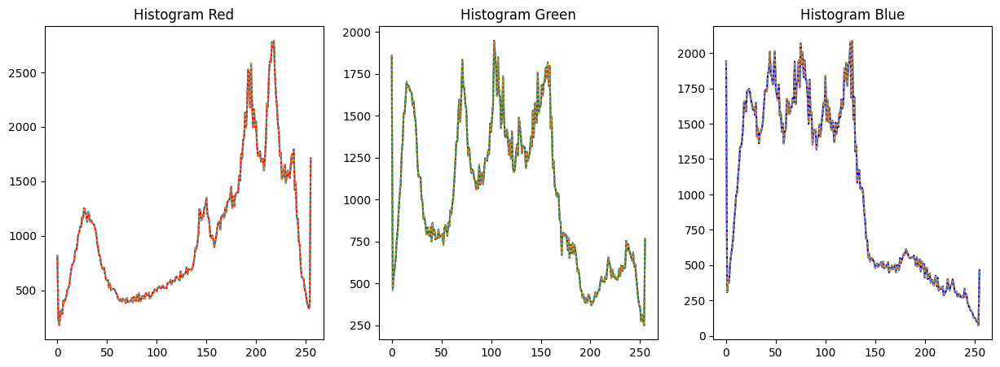

In [7]:
# Membaca citra Lena
img = cv.imread('/content/drive/MyDrive/PCVK/lena.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img)

# =========================
# 1. Histogram Manual
# =========================

red_manual = [0]*256
green_manual = [0]*256
blue_manual = [0]*256

for y in range(height):
    for x in range(width):
        red_manual[img[y][x][0]] += 1
        green_manual[img[y][x][1]] += 1
        blue_manual[img[y][x][2]] += 1


# =========================
# 2. Histogram NumPy
# =========================

red_numpy, _ = np.histogram(img[:,:,0], bins=256, range=(0,256))
green_numpy, _ = np.histogram(img[:,:,1], bins=256, range=(0,256))
blue_numpy, _ = np.histogram(img[:,:,2], bins=256, range=(0,256))


# =========================
# 3. Histogram OpenCV calcHist
# =========================

red_cv = cv.calcHist([img], [0], None, [256], [0,256]).flatten()
green_cv = cv.calcHist([img], [1], None, [256], [0,256]).flatten()
blue_cv = cv.calcHist([img], [2], None, [256], [0,256]).flatten()


# =========================
# Perbandingan Selisih
# =========================

print("Selisih Manual vs NumPy")
print("Red :", np.max(np.abs(np.array(red_manual)-red_numpy)))
print("Green :", np.max(np.abs(np.array(green_manual)-green_numpy)))
print("Blue :", np.max(np.abs(np.array(blue_manual)-blue_numpy)))


print("\nSelisih Manual vs OpenCV")
print("Red :", np.max(np.abs(np.array(red_manual)-red_cv)))
print("Green :", np.max(np.abs(np.array(green_manual)-green_cv)))
print("Blue :", np.max(np.abs(np.array(blue_manual)-blue_cv)))

print("\nSelisih NumPy vs OpenCV")
print("Red :", np.max(np.abs(red_numpy - red_cv)))
print("Green :", np.max(np.abs(green_numpy - green_cv)))
print("Blue :", np.max(np.abs(blue_numpy - blue_cv)))

# =========================
# Plot Histogram
# =========================

x = np.arange(256)

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.title("Histogram Red")
plt.plot(x, red_manual, color='red')
plt.plot(x, red_numpy, '--')
plt.plot(x, red_cv, ':')

plt.subplot(1,3,2)
plt.title("Histogram Green")
plt.plot(x, green_manual, color='green')
plt.plot(x, green_numpy, '--')
plt.plot(x, green_cv, ':')

plt.subplot(1,3,3)
plt.title("Histogram Blue")
plt.plot(x, blue_manual, color='blue')
plt.plot(x, blue_numpy, '--')
plt.plot(x, blue_cv, ':')

plt.show()

Selisih Manual vs NumPy
Red : 0
Green : 0
Blue : 0

Selisih Manual vs OpenCV
Red : 0.0
Green : 0.0
Blue : 0.0

Selisih NumPy vs OpenCV
Red : 0.0
Green : 0.0
Blue : 0.0


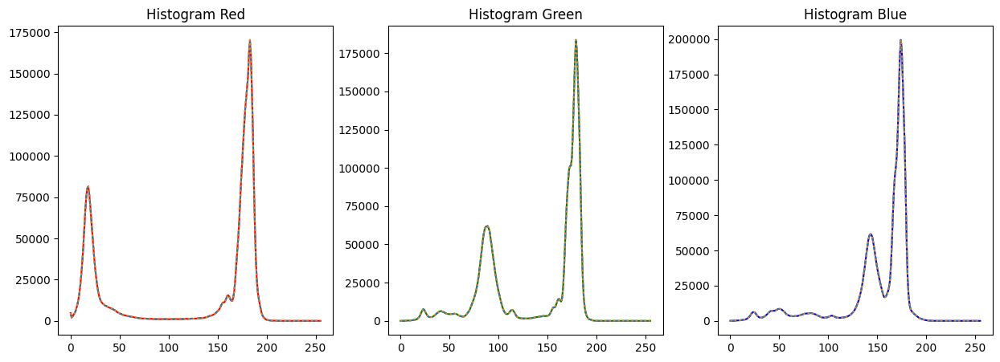

In [8]:
# Membaca citra Lena
img = cv.imread('/content/drive/MyDrive/PCVK/KTM lama.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img)

# =========================
# 1. Histogram Manual
# =========================

red_manual = [0]*256
green_manual = [0]*256
blue_manual = [0]*256

for y in range(height):
    for x in range(width):
        red_manual[img[y][x][0]] += 1
        green_manual[img[y][x][1]] += 1
        blue_manual[img[y][x][2]] += 1


# =========================
# 2. Histogram NumPy
# =========================

red_numpy, _ = np.histogram(img[:,:,0], bins=256, range=(0,256))
green_numpy, _ = np.histogram(img[:,:,1], bins=256, range=(0,256))
blue_numpy, _ = np.histogram(img[:,:,2], bins=256, range=(0,256))


# =========================
# 3. Histogram OpenCV calcHist
# =========================

red_cv = cv.calcHist([img], [0], None, [256], [0,256]).flatten()
green_cv = cv.calcHist([img], [1], None, [256], [0,256]).flatten()
blue_cv = cv.calcHist([img], [2], None, [256], [0,256]).flatten()


# =========================
# Perbandingan Selisih
# =========================

print("Selisih Manual vs NumPy")
print("Red :", np.max(np.abs(np.array(red_manual)-red_numpy)))
print("Green :", np.max(np.abs(np.array(green_manual)-green_numpy)))
print("Blue :", np.max(np.abs(np.array(blue_manual)-blue_numpy)))


print("\nSelisih Manual vs OpenCV")
print("Red :", np.max(np.abs(np.array(red_manual)-red_cv)))
print("Green :", np.max(np.abs(np.array(green_manual)-green_cv)))
print("Blue :", np.max(np.abs(np.array(blue_manual)-blue_cv)))

print("\nSelisih NumPy vs OpenCV")
print("Red :", np.max(np.abs(red_numpy - red_cv)))
print("Green :", np.max(np.abs(green_numpy - green_cv)))
print("Blue :", np.max(np.abs(blue_numpy - blue_cv)))

# =========================
# Plot Histogram
# =========================

x = np.arange(256)

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.title("Histogram Red")
plt.plot(x, red_manual, color='red')
plt.plot(x, red_numpy, '--')
plt.plot(x, red_cv, ':')

plt.subplot(1,3,2)
plt.title("Histogram Green")
plt.plot(x, green_manual, color='green')
plt.plot(x, green_numpy, '--')
plt.plot(x, green_cv, ':')

plt.subplot(1,3,3)
plt.title("Histogram Blue")
plt.plot(x, blue_manual, color='blue')
plt.plot(x, blue_numpy, '--')
plt.plot(x, blue_cv, ':')

plt.show()

**Jawab Pertanyaan E1 No2**

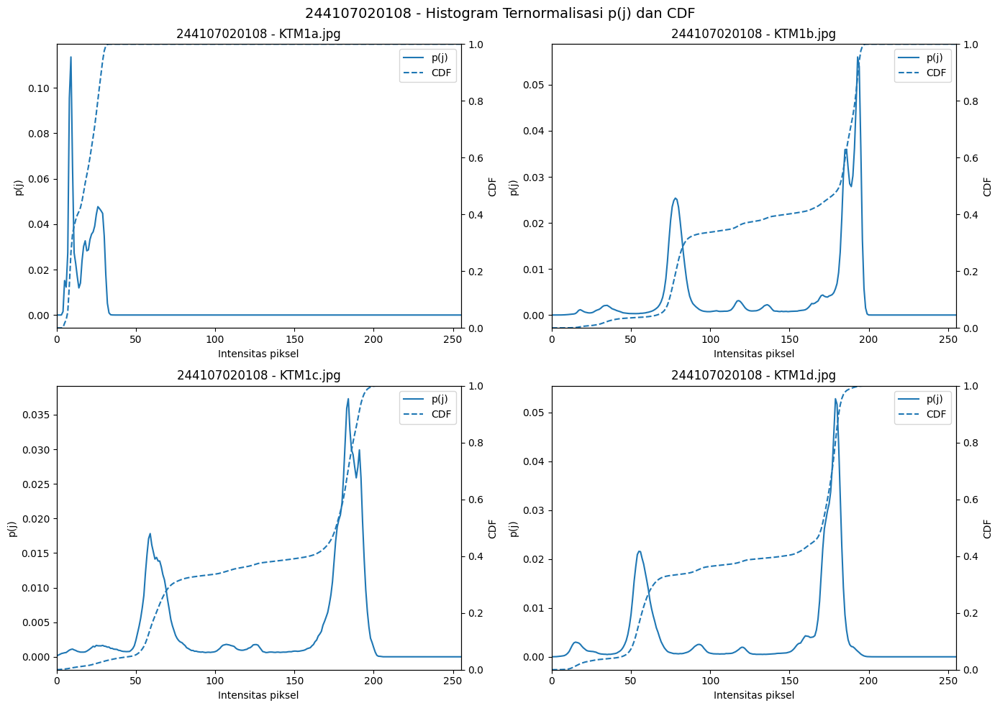


Rata-rata intensitas:
KTM1a.jpg : 17.8
KTM1b.jpg : 144.75
KTM1c.jpg : 138.02
KTM1d.jpg : 130.31

Citra paling gelap  : KTM1a.jpg
Citra paling terang : KTM1b.jpg


In [9]:
BASE = '/content/drive/MyDrive/PCVK'

nama_file = [
    'KTM1a.jpg',
    'KTM1b.jpg',
    'KTM1c.jpg',
    'KTM1d.jpg'
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

rata_rata = {}

for ax, nama in zip(axes.flat, nama_file):

    path = BASE + '/' + nama
    img = cv.imread(path, cv.IMREAD_GRAYSCALE)

    if img is None:
        print('Gagal membaca:', path)
        continue

    hist, _ = np.histogram(
        img.flatten(),
        bins=256,
        range=[0, 256]
    )

    # Histogram ternormalisasi p(j)
    p = hist / img.size

    # CDF
    cdf = np.cumsum(p)

    rata_rata[nama] = img.mean()

    ax.plot(np.arange(256), p, label='p(j)')
    ax.set_title(NIM + ' - ' + nama)
    ax.set_xlabel('Intensitas piksel')
    ax.set_ylabel('p(j)')
    ax.set_xlim([0, 255])

    ax2 = ax.twinx()
    ax2.plot(
        np.arange(256),
        cdf,
        linestyle='--',
        label='CDF'
    )

    ax2.set_ylabel('CDF')
    ax2.set_ylim([0, 1])

    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()

    ax.legend(
        lines1 + lines2,
        labels1 + labels2,
        loc='best'
    )

plt.suptitle(
    NIM + ' - Histogram Ternormalisasi p(j) dan CDF',
    fontsize=14
)

plt.tight_layout()
plt.show()

print('\nRata-rata intensitas:')

for nama, nilai in rata_rata.items():
    print(nama, ':', round(nilai, 2))

paling_gelap = min(rata_rata, key=rata_rata.get)
paling_terang = max(rata_rata, key=rata_rata.get)

print('\nCitra paling gelap  :', paling_gelap)
print('Citra paling terang :', paling_terang)

**Penjelasan**

Kurva CDF KTM1a.jpg naik cepat pada intensitas rendah karena citra diambil di ruangan gelap, sehingga sebagian besar piksel bernilai gelap. Sementara itu, CDF KTM1b.jpg bergeser ke intensitas yang lebih tinggi karena menggunakan pencahayaan lampu ruangan. Hasil ini sesuai dengan rata-rata intensitas, yaitu KTM1a sebesar 17,8 sebagai citra paling gelap dan KTM1b sebesar 144,75 sebagai citra paling terang.

**Jawab Pertanyaan E1 No3**

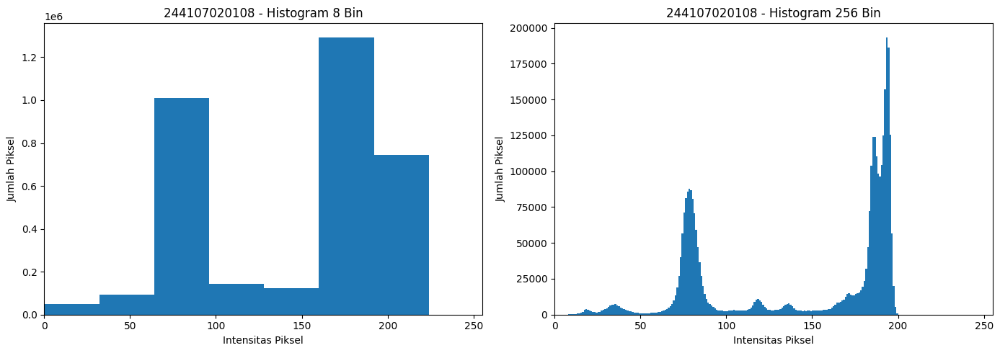

Jumlah bin PARAM : 8
Jumlah bin pembanding : 256


In [10]:
path = '/content/drive/MyDrive/PCVK/KTM1b.jpg'

# Baca grayscale
img = cv.imread(path, cv.IMREAD_GRAYSCALE)

if img is None:
    print('Gambar tidak ditemukan:', path)
else:
    # Histogram sesuai PARAM['bins']
    hist_param, bin_param = np.histogram(
        img.flatten(),
        bins=PARAM['bins'],
        range=[0, 256]
    )

    # Histogram 256 bin
    hist_256, bin_256 = np.histogram(
        img.flatten(),
        bins=256,
        range=[0, 256]
    )

    # Tampilkan berdampingan
    plt.figure(figsize=(14, 5))

    # PARAM['bins']
    plt.subplot(1, 2, 1)
    plt.bar(
        bin_param[:-1],
        hist_param,
        width=np.diff(bin_param),
        align='edge'
    )
    plt.title(NIM + " - Histogram " + str(PARAM['bins']) + " Bin")
    plt.xlabel('Intensitas Piksel')
    plt.ylabel('Jumlah Piksel')
    plt.xlim([0, 255])

    # 256 bin
    plt.subplot(1, 2, 2)
    plt.bar(
        bin_256[:-1],
        hist_256,
        width=np.diff(bin_256),
        align='edge'
    )
    plt.title(NIM + " - Histogram 256 Bin")
    plt.xlabel('Intensitas Piksel')
    plt.ylabel('Jumlah Piksel')
    plt.xlim([0, 255])

    plt.tight_layout()
    plt.show()

    print("Jumlah bin PARAM :", PARAM['bins'])
    print("Jumlah bin pembanding : 256")

**Penjelasan**

Ketika jumlah bin dikurangi dari 256 menjadi 8, detail distribusi intensitas piksel menjadi berkurang karena beberapa nilai intensitas digabung ke dalam satu bin.

**E-2 PERCOBAAN HISTOGRAM EQUALIZATION**

**Jawab No 1 E-2**

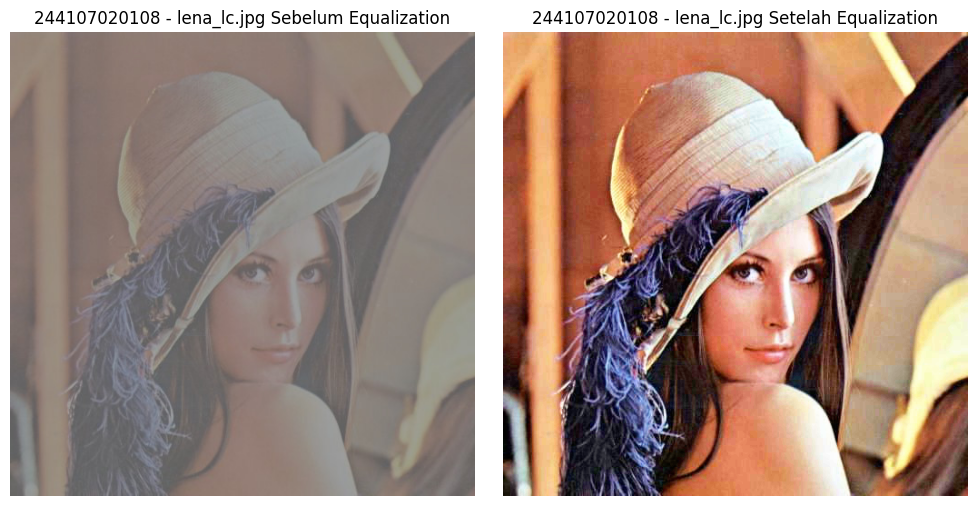

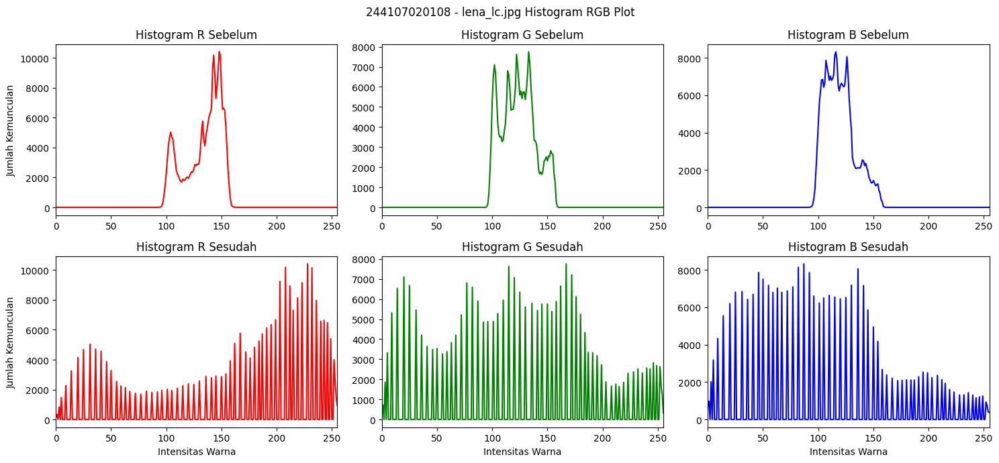

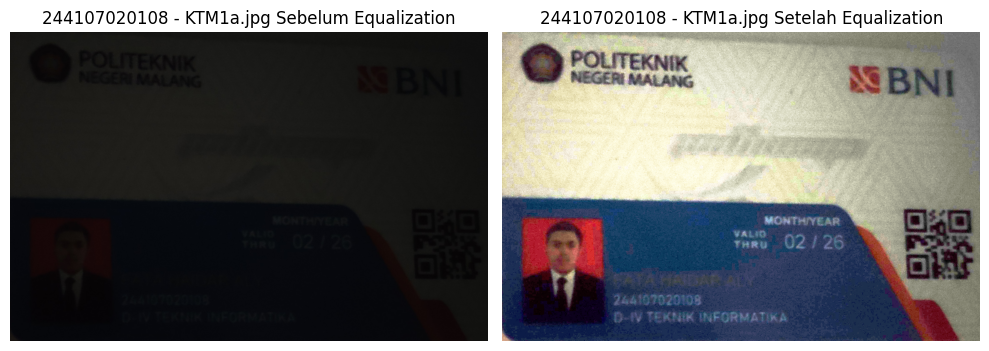

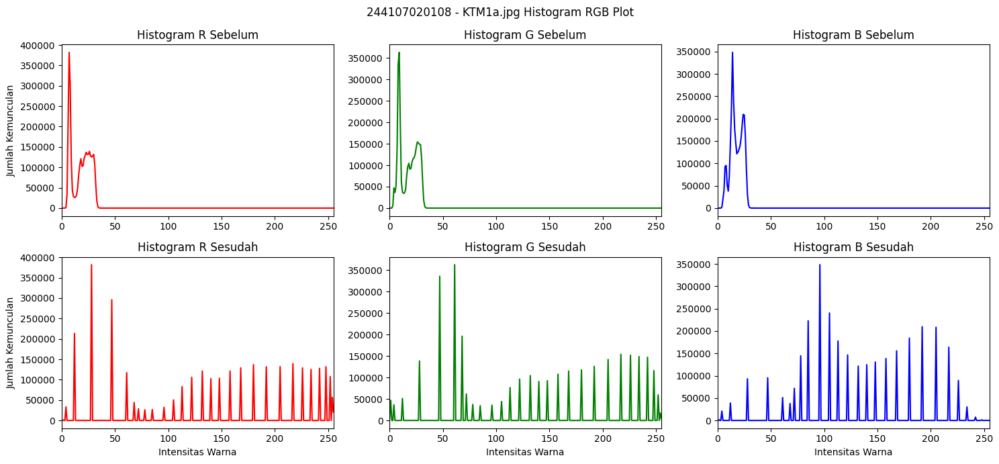

In [22]:
BASE = '/content/drive/MyDrive/PCVK'


def equalization_manual(image):
    pixel = image.flatten()

    hist = np.zeros(256, dtype=np.int64)

    for nilai in pixel:
        hist[nilai] += 1

    cdf = np.cumsum(hist)
    cdf_normal = cdf / pixel.size

    transform = np.round(cdf_normal * 255).astype(np.uint8)

    hasil = transform[image]

    return hasil


def tampilkan_equalization(path, nama):
    image = cv.imread(path)

    if image is None:
        print('Gambar tidak ditemukan:', path)
        return

    hasil = equalization_manual(image)

    # ==========================
    # CITRA SEBELUM DAN SESUDAH
    # ==========================
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
    plt.title(NIM + ' - ' + nama + ' Sebelum Equalization')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB))
    plt.title(NIM + ' - ' + nama + ' Setelah Equalization')
    plt.axis('off')

    plt.tight_layout()
    plt.show()


    # ==========================
    # HISTOGRAM RGB
    # ==========================
    b, g, r = cv.split(image)
    b_eq, g_eq, r_eq = cv.split(hasil)

    plt.figure(figsize=(15, 7))

    # R sebelum
    plt.subplot(2, 3, 1)
    hist_r = cv.calcHist([r], [0], None, [256], [0, 256])
    plt.plot(hist_r, color='red')
    plt.title('Histogram R Sebelum')
    plt.ylabel('Jumlah Kemunculan')
    plt.xlim([0, 255])

    # G sebelum
    plt.subplot(2, 3, 2)
    hist_g = cv.calcHist([g], [0], None, [256], [0, 256])
    plt.plot(hist_g, color='green')
    plt.title('Histogram G Sebelum')
    plt.xlim([0, 255])

    # B sebelum
    plt.subplot(2, 3, 3)
    hist_b = cv.calcHist([b], [0], None, [256], [0, 256])
    plt.plot(hist_b, color='blue')
    plt.title('Histogram B Sebelum')
    plt.xlim([0, 255])

    # R sesudah
    plt.subplot(2, 3, 4)
    hist_r_eq = cv.calcHist([r_eq], [0], None, [256], [0, 256])
    plt.plot(hist_r_eq, color='red')
    plt.title('Histogram R Sesudah')
    plt.xlabel('Intensitas Warna')
    plt.ylabel('Jumlah Kemunculan')
    plt.xlim([0, 255])

    # G sesudah
    plt.subplot(2, 3, 5)
    hist_g_eq = cv.calcHist([g_eq], [0], None, [256], [0, 256])
    plt.plot(hist_g_eq, color='green')
    plt.title('Histogram G Sesudah')
    plt.xlabel('Intensitas Warna')
    plt.xlim([0, 255])

    # B sesudah
    plt.subplot(2, 3, 6)
    hist_b_eq = cv.calcHist([b_eq], [0], None, [256], [0, 256])
    plt.plot(hist_b_eq, color='blue')
    plt.title('Histogram B Sesudah')
    plt.xlabel('Intensitas Warna')
    plt.xlim([0, 255])

    plt.suptitle(NIM + ' - ' + nama + ' Histogram RGB Plot')
    plt.tight_layout()
    plt.show()


# =========================
# TAHAP 1 - LENA
# =========================
tampilkan_equalization(
    BASE + '/lena_lc.jpg',
    'lena_lc.jpg'
)


# =========================
# TAHAP 2 - KTM
# =========================
tampilkan_equalization(
    BASE + '/KTM1a.jpg',
    'KTM1a.jpg'
)

**Jawab No 2 E-2**

lena_lc.jpg
Selisih maksimum = 68


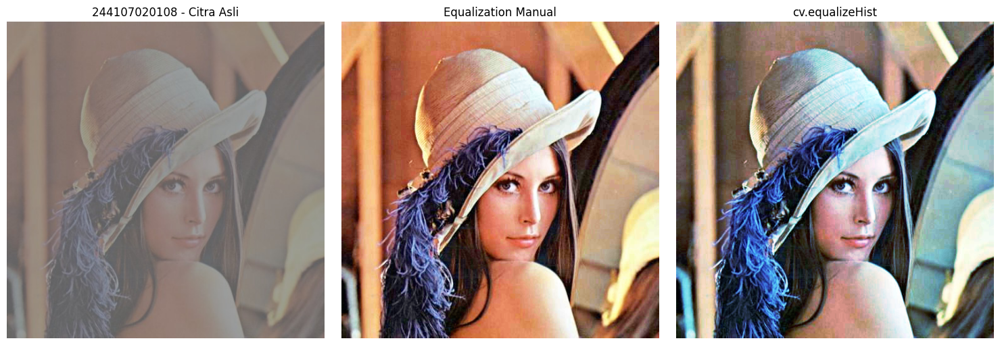

KTM1a.jpg
Selisih maksimum = 41


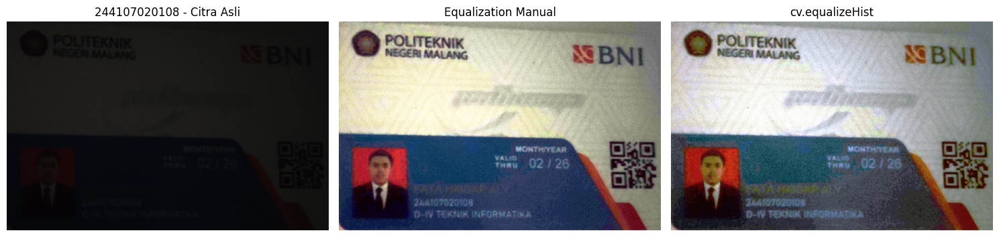

In [26]:
BASE = '/content/drive/MyDrive/PCVK'


def bandingkan_manual_cv(path, nama):
    image = cv.imread(path)

    if image is None:
        print('Gambar tidak ditemukan:', path)
        return

    # ==========================================
    # 1. HASIL MANUAL
    # pakai fungsi manual dari langkah sebelumnya
    # ==========================================
    hasil_manual = equalization_manual(image)


    # ==========================================
    # 2. HASIL cv.equalizeHist
    # sesuai potongan kode pada modul
    # ==========================================
    b, g, r = cv.split(image)

    b_equalized = cv.equalizeHist(b)
    g_equalized = cv.equalizeHist(g)
    r_equalized = cv.equalizeHist(r)

    hasil_cv = cv.merge([
        b_equalized,
        g_equalized,
        r_equalized
    ])


    # ==========================================
    # 3. SELISIH MAKSIMUM
    # ==========================================
    selisih = cv.absdiff(hasil_manual, hasil_cv)
    max_selisih = np.max(selisih)

    print('====================================')
    print(nama)
    print('Selisih maksimum =', max_selisih)
    print('====================================')


    # ==========================================
    # 4. TAMPILKAN HASIL
    # ==========================================
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
    plt.title(NIM + ' - Citra Asli')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(cv.cvtColor(hasil_manual, cv.COLOR_BGR2RGB))
    plt.title('Equalization Manual')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(cv.cvtColor(hasil_cv, cv.COLOR_BGR2RGB))
    plt.title('cv.equalizeHist')
    plt.axis('off')

    plt.tight_layout()
    plt.show()


# ===============================
# lena_lc.jpg
# ===============================
bandingkan_manual_cv(
    BASE + '/lena_lc.jpg',
    'lena_lc.jpg'
)


# ===============================
# KTM1a.jpg
# ===============================
bandingkan_manual_cv(
    BASE + '/KTM1a.jpg',
    'KTM1a.jpg'
)

**Penjelasan**

Selisih yang tidak nol terjadi karena terdapat perbedaan proses perhitungan antara implementasi manual dan cv.equalizeHist(). Pada implementasi manual, transformasi histogram diterapkan berdasarkan CDF yang dihitung secara manual, sedangkan cv.equalizeHist() melakukan ekualisasi pada masing-masing kanal warna menggunakan perhitungan internal OpenCV. Perbedaan normalisasi CDF dan pembulatan nilai intensitas juga dapat menyebabkan nilai piksel hasil akhir tidak sama persis

**Jawab No 3 E-2**

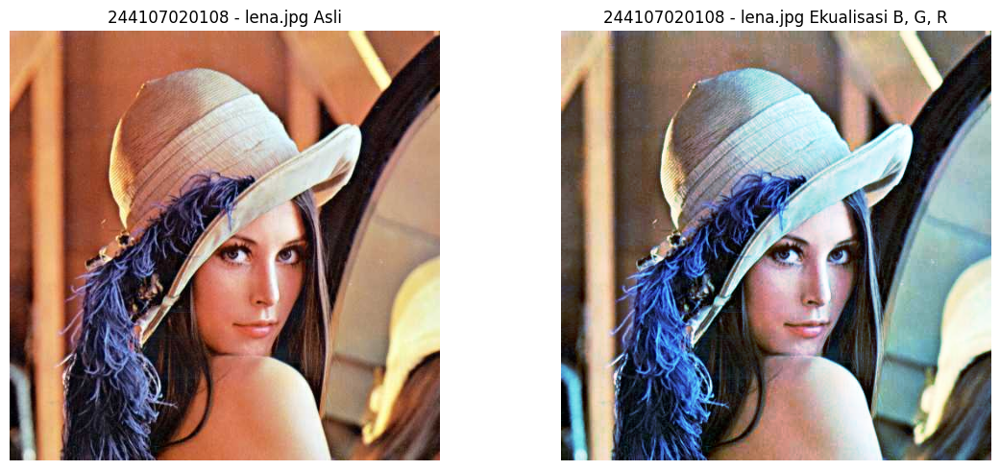

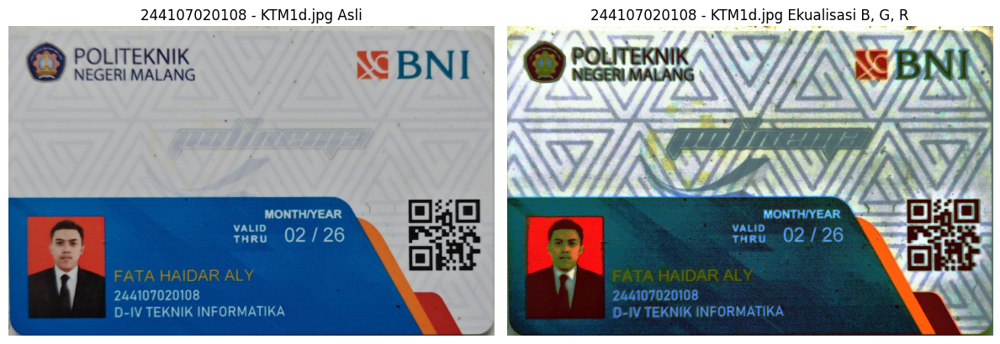

In [27]:
BASE = '/content/drive/MyDrive/PCVK'


def equalization_rgb(path, nama):
    bgr = cv.imread(path)

    if bgr is None:
        print('Gambar tidak ditemukan:', path)
        return

    # Pisahkan kanal B, G, R
    kanal = list(cv.split(bgr))

    # Equalization tiap kanal
    for i in range(3):
        kanal[i] = cv.equalizeHist(kanal[i])

    # Gabungkan kembali
    he_rgb = cv.merge(kanal)

    # Tampilkan sebelum dan sesudah
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(cv.cvtColor(bgr, cv.COLOR_BGR2RGB))
    plt.title(NIM + ' - ' + nama + ' Asli')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(cv.cvtColor(he_rgb, cv.COLOR_BGR2RGB))
    plt.title(NIM + ' - ' + nama + ' Ekualisasi B, G, R')
    plt.axis('off')

    plt.tight_layout()
    plt.show()


# =========================
# TAHAP 1 - lena.jpg
# =========================
equalization_rgb(
    BASE + '/lena.jpg',
    'lena.jpg'
)


# =========================
# TAHAP 2 - KTM1d.jpg
# =========================
equalization_rgb(
    BASE + '/KTM1d.jpg',
    'KTM1d.jpg'
)

**Penjelasan**

kontras citra meningkat tetapi warna citra juga mengalami perubahan. Pada lena.jpg, beberapa bagian warna terlihat lebih kuat dan berbeda dari citra asli. Hal serupa juga terjadi pada KTM1d.jpg, yaitu warna setelah ekualisasi tidak sepenuhnya sama dengan warna asli.

**Jawab No 4 E-2**

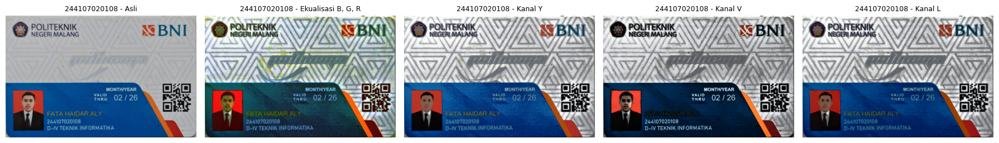

Cara                    geser Hue (der)    rerata terang
Asli                               0.00            130.4
Ekualisasi B, G, R                28.99            127.2
Kanal Y                            0.97            131.3
Kanal V                            3.47            115.9
Kanal L                            7.41            123.4


In [28]:
BASE = '/content/drive/MyDrive/PCVK'

# =========================
# BACA KTM1d.jpg
# =========================
bgr = cv.imread(BASE + '/KTM1d.jpg')

if bgr is None:
    print('Gambar KTM1d.jpg tidak ditemukan')

else:
    # ==================================================
    # CARA 1 - Equalization kanal B, G, R satu per satu
    # ==================================================
    kanal = list(cv.split(bgr))

    for i in range(3):
        kanal[i] = cv.equalizeHist(kanal[i])

    he_rgb = cv.merge(kanal)


    # ==================================================
    # CARA 2A - YCrCb, equalization hanya kanal Y
    # ==================================================
    ycrcb = cv.cvtColor(bgr, cv.COLOR_BGR2YCrCb)

    y, cr, cb = cv.split(ycrcb)

    he_y = cv.cvtColor(
        cv.merge([
            cv.equalizeHist(y),
            cr,
            cb
        ]),
        cv.COLOR_YCrCb2BGR
    )


    # ==================================================
    # CARA 2B - HSV, equalization hanya kanal V
    # ==================================================
    hsv = cv.cvtColor(bgr, cv.COLOR_BGR2HSV)

    h, sat, v = cv.split(hsv)

    he_v = cv.cvtColor(
        cv.merge([
            h,
            sat,
            cv.equalizeHist(v)
        ]),
        cv.COLOR_HSV2BGR
    )


    # ==================================================
    # CARA 2C - LAB, equalization hanya kanal L
    # ==================================================
    lab = cv.cvtColor(bgr, cv.COLOR_BGR2LAB)

    l, a, b = cv.split(lab)

    he_l = cv.cvtColor(
        cv.merge([
            cv.equalizeHist(l),
            a,
            b
        ]),
        cv.COLOR_LAB2BGR
    )


    # ==================================================
    # TAMPILKAN 5 CITRA BERDAMPINGAN
    # ==================================================
    judul = [
        'Asli',
        'Ekualisasi B, G, R',
        'Kanal Y',
        'Kanal V',
        'Kanal L'
    ]

    citra = [
        bgr,
        he_rgb,
        he_y,
        he_v,
        he_l
    ]

    plt.figure(figsize=(18, 4))

    for i, (c, t) in enumerate(zip(citra, judul), 1):
        plt.subplot(1, 5, i)

        plt.imshow(
            cv.cvtColor(c, cv.COLOR_BGR2RGB)
        )

        plt.title(
            NIM + ' - ' + t,
            fontsize=9
        )

        plt.axis('off')

    plt.tight_layout()
    plt.show()


    # ==================================================
    # FUNGSI MENGHITUNG PERGESERAN HUE
    # ==================================================
    def geser_hue(asli, hasil):
        h1 = cv.cvtColor(
            asli,
            cv.COLOR_BGR2HSV
        )[:, :, 0].astype(np.int16)

        h2 = cv.cvtColor(
            hasil,
            cv.COLOR_BGR2HSV
        )[:, :, 0].astype(np.int16)

        d = np.abs(h1 - h2)

        # Hue OpenCV melingkar 0 - 179
        d = np.minimum(d, 180 - d)

        return d.mean()


    # ==================================================
    # TAMPILKAN HASIL PENGUKURAN
    # ==================================================
    print(
        '%-22s %16s %16s' %
        ('Cara', 'geser Hue (der)', 'rerata terang')
    )

    for t, c in zip(judul, citra):
        print(
            '%-22s %16.2f %16.1f' %
            (
                t,
                geser_hue(bgr, c) * 2,
                cv.cvtColor(
                    c,
                    cv.COLOR_BGR2GRAY
                ).mean()
            )
        )

1. Pergeseran Hue paling besar
Cara yang menghasilkan pergeseran Hue paling besar adalah ekualisasi kanal B, G, dan R secara terpisah, yaitu sebesar 28,99°.
Hal ini menunjukkan bahwa mengekualisasi setiap kanal warna secara terpisah menyebabkan perubahan warna yang cukup besar karena masing-masing kanal mengalami transformasi intensitas yang berbeda.
2. Mengapa ekualisasi kanal terang tetap memiliki Hue yang tidak nol?
Walaupun hanya kanal terang seperti Y, V, atau L yang diekualisasi, nilai Hue tetap dapat berubah sedikit ketika citra dikonversi kembali ke BGR.
Penyebabnya adalah proses konversi ruang warna melibatkan perhitungan numerik. Nilai hasil konversi harus dibulatkan ke nilai integer dan dipotong agar tetap berada dalam rentang 0–255. Perubahan kecil akibat pembulatan dan pemotongan tersebut dapat mengubah perbandingan nilai B, G, dan R sehingga Hue setelah konversi tidak persis sama dengan citra asli.
Hal ini terlihat pada hasilmu:
- Y = 0,97°
- V = 3,47°
- L = 7,41°
Jadi meskipun informasi warna tidak langsung diekualisasi, proses konversi kembali ke BGR tetap dapat menghasilkan sedikit pergeseran warna.
3. Kanal yang paling sesuai untuk foto KTM
Dari hasilmu, kanal Y (YCrCb) paling sesuai untuk foto KTM.
Alasannya, kanal Y memiliki pergeseran Hue paling kecil di antara ketiga kanal terang, yaitu hanya 0,97°, sehingga warna hasilnya paling mendekati citra asli. Rerata kecerahannya juga meningkat sedikit dari 130,4 menjadi 131,3, sehingga citra tidak menjadi terlalu gelap atau terlalu terang.
Secara visual, bagian foto pemilik kartu, warna biru pada bagian bawah kartu, logo, serta tulisan pada kartu masih terlihat natural dan detailnya tetap jelas. Dibandingkan kanal V dan L, kanal Y memberikan peningkatan kontras dengan perubahan warna yang paling kecil.

4.Ulangi kanal Y menggunakan CLAHE

Equalization Y biasa
Pergeseran Hue : 0.97
Rerata terang  : 131.3

CLAHE kanal Y
Pergeseran Hue : 0.04
Rerata terang  : 138.4


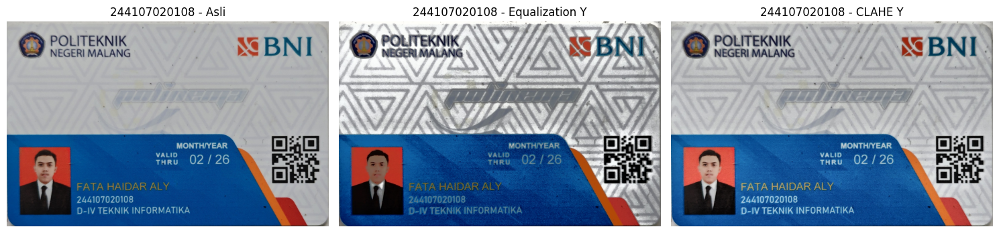

In [29]:
# CLAHE pada kanal Y
ycrcb = cv.cvtColor(bgr, cv.COLOR_BGR2YCrCb)
y, cr, cb = cv.split(ycrcb)

clahe = cv.createCLAHE(
    clipLimit=PARAM['clip'],
    tileGridSize=(PARAM['tile'], PARAM['tile'])
)

y_clahe = clahe.apply(y)

he_y_clahe = cv.cvtColor(
    cv.merge([y_clahe, cr, cb]),
    cv.COLOR_YCrCb2BGR
)

# Hitung pergeseran Hue dan rerata terang
hue_clahe = geser_hue(bgr, he_y_clahe) * 2

terang_clahe = cv.cvtColor(
    he_y_clahe,
    cv.COLOR_BGR2GRAY
).mean()

print('Equalization Y biasa')
print('Pergeseran Hue :', 0.97)
print('Rerata terang  :', 131.3)

print('\nCLAHE kanal Y')
print('Pergeseran Hue :', round(hue_clahe, 2))
print('Rerata terang  :', round(terang_clahe, 1))


# Tampilkan perbandingan
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(cv.cvtColor(bgr, cv.COLOR_BGR2RGB))
plt.title(NIM + ' - Asli')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(cv.cvtColor(he_y, cv.COLOR_BGR2RGB))
plt.title(NIM + ' - Equalization Y')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv.cvtColor(he_y_clahe, cv.COLOR_BGR2RGB))
plt.title(NIM + ' - CLAHE Y')
plt.axis('off')

plt.tight_layout()
plt.show()

**JAWAB PERTANYAAN PRAKTIKUM E2**

**1. Ekualisasi global pada citra KTM Anda**


PSNR Asli vs Manual       : 5.68 dB
PSNR Asli vs equalizeHist : 5.68 dB


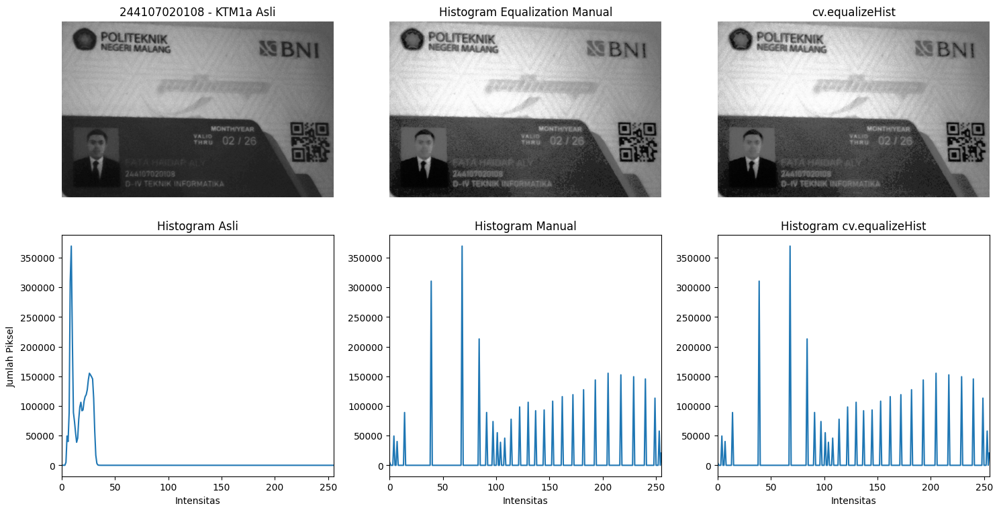

In [30]:
BASE = '/content/drive/MyDrive/PCVK'


# ==========================================
# HISTOGRAM EQUALIZATION MANUAL GRAYSCALE
# ==========================================
def equalization_manual_gray(gray):
    hist = np.zeros(256, dtype=np.int64)

    for y in range(gray.shape[0]):
        for x in range(gray.shape[1]):
            hist[gray[y, x]] += 1

    # CDF
    cdf = np.cumsum(hist)

    # Normalisasi
    cdf_normal = cdf / gray.size

    # Transformasi ke 0 - 255
    transform = np.round(
        cdf_normal * 255
    ).astype(np.uint8)

    # Terapkan transformasi
    hasil = transform[gray]

    return hasil


# ==========================================
# BACA KTM1a.jpg SEBAGAI GRAYSCALE
# ==========================================
gray = cv.imread(
    BASE + '/KTM1a.jpg',
    cv.IMREAD_GRAYSCALE
)

if gray is None:
    print('KTM1a.jpg tidak ditemukan')

else:
    # ======================================
    # EQUALIZATION MANUAL
    # ======================================
    hasil_manual = equalization_manual_gray(gray)

    # ======================================
    # cv.equalizeHist
    # ======================================
    hasil_cv = cv.equalizeHist(gray)


    # ======================================
    # PSNR
    # ======================================
    psnr_manual = cv.PSNR(
        gray,
        hasil_manual
    )

    psnr_cv = cv.PSNR(
        gray,
        hasil_cv
    )

    print('PSNR Asli vs Manual       :',
          round(psnr_manual, 2), 'dB')

    print('PSNR Asli vs equalizeHist :',
          round(psnr_cv, 2), 'dB')


    # ======================================
    # HISTOGRAM
    # ======================================
    hist_asli = cv.calcHist(
        [gray], [0], None,
        [256], [0, 256]
    )

    hist_manual = cv.calcHist(
        [hasil_manual], [0], None,
        [256], [0, 256]
    )

    hist_cv = cv.calcHist(
        [hasil_cv], [0], None,
        [256], [0, 256]
    )


    # ======================================
    # TAMPILKAN DALAM SATU LAYOUT
    # ======================================
    plt.figure(figsize=(15, 8))


    # Citra asli
    plt.subplot(2, 3, 1)

    plt.imshow(
        gray,
        cmap='gray'
    )

    plt.title(
        NIM + ' - KTM1a Asli'
    )

    plt.axis('off')


    # Manual
    plt.subplot(2, 3, 2)

    plt.imshow(
        hasil_manual,
        cmap='gray'
    )

    plt.title(
        'Histogram Equalization Manual'
    )

    plt.axis('off')


    # equalizeHist
    plt.subplot(2, 3, 3)

    plt.imshow(
        hasil_cv,
        cmap='gray'
    )

    plt.title(
        'cv.equalizeHist'
    )

    plt.axis('off')


    # Histogram asli
    plt.subplot(2, 3, 4)

    plt.plot(hist_asli)

    plt.title('Histogram Asli')
    plt.xlabel('Intensitas')
    plt.ylabel('Jumlah Piksel')
    plt.xlim([0, 255])


    # Histogram manual
    plt.subplot(2, 3, 5)

    plt.plot(hist_manual)

    plt.title('Histogram Manual')
    plt.xlabel('Intensitas')
    plt.xlim([0, 255])


    # Histogram cv.equalizeHist
    plt.subplot(2, 3, 6)

    plt.plot(hist_cv)

    plt.title('Histogram cv.equalizeHist')
    plt.xlabel('Intensitas')
    plt.xlim([0, 255])


    plt.tight_layout()
    plt.show()

**Penjelasan**

Nilai PSNR dapat menurun setelah histogram equalization walaupun citra terlihat lebih jelas. Hal ini karena PSNR mengukur kesamaan nilai piksel antara citra asli dan citra hasil.Histogram equalization memang sengaja mengubah banyak nilai intensitas piksel untuk meningkatkan kontras. Perubahan tersebut memperbesar perbedaan antara citra asli dan hasil sehingga nilai PSNR menjadi lebih rendah.

PSNR kurang tepat jika digunakan sebagai satu-satunya ukuran keterbacaan citra. Nilai PSNR yang tinggi menunjukkan citra hasil mirip dengan citra asli, tetapi tidak selalu berarti teks atau detail lebih mudah dibaca. Pada histogram equalization, nilai PSNR dapat menurun justru karena kontras ditingkatkan sehingga informasi pada citra gelap menjadi lebih terlihat.

**2. Ekualisasi lokal dengan CLAHE pada citra KTM Anda**

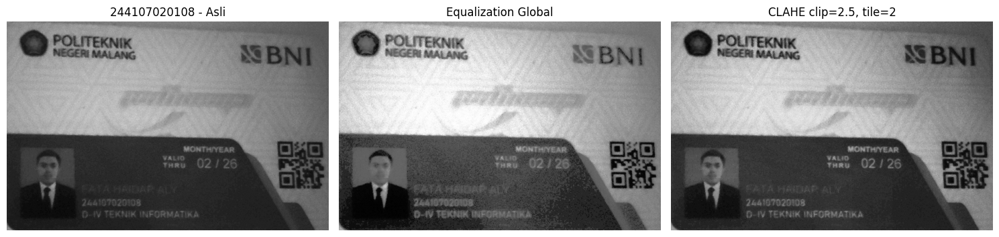

In [31]:
BASE = '/content/drive/MyDrive/PCVK'

# ==========================================
# BACA KTM1a.jpg GRAYSCALE
# ==========================================
gray = cv.imread(
    BASE + '/KTM1a.jpg',
    cv.IMREAD_GRAYSCALE
)

if gray is None:
    print('KTM1a.jpg tidak ditemukan')

else:
    # ======================================
    # EQUALIZATION GLOBAL
    # ======================================
    global_eq = cv.equalizeHist(gray)

    # ======================================
    # CLAHE SESUAI PARAMETER NIM
    # ======================================
    clahe = cv.createCLAHE(
        clipLimit=PARAM['clip'],
        tileGridSize=(
            PARAM['tile'],
            PARAM['tile']
        )
    )

    clahe_param = clahe.apply(gray)

    # ======================================
    # TAMPILKAN PERBANDINGAN
    # ======================================
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(gray, cmap='gray')
    plt.title(NIM + ' - Asli')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(global_eq, cmap='gray')
    plt.title('Equalization Global')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(clahe_param, cmap='gray')
    plt.title(
        'CLAHE clip=' +
        str(PARAM['clip']) +
        ', tile=' +
        str(PARAM['tile'])
    )
    plt.axis('off')

    plt.tight_layout()
    plt.show()

**Jawaban bagian a**

Pada hasil percobaan, nama dan NIM lebih terbaca pada citra hasil CLAHE dibandingkan ekualisasi global. CLAHE mampu meningkatkan kontras pada area lokal kartu tanpa terlalu meningkatkan kontras seluruh citra.

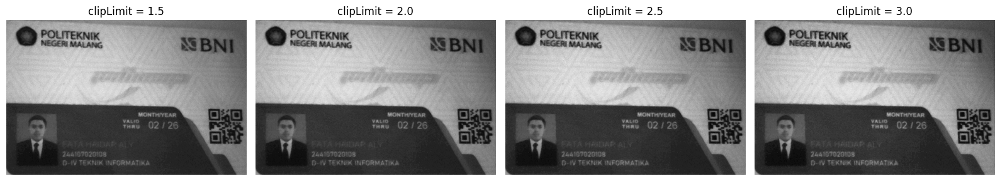

In [32]:
clip_values = [
    1.5,
    2.0,
    PARAM['clip'],   # 2.5
    3.0
]

hasil_clahe = []

plt.figure(figsize=(16, 4))

for i, clip in enumerate(clip_values, 1):

    clahe = cv.createCLAHE(
        clipLimit=clip,
        tileGridSize=(
            PARAM['tile'],
            PARAM['tile']
        )
    )

    hasil = clahe.apply(gray)
    hasil_clahe.append(hasil)

    plt.subplot(1, 4, i)
    plt.imshow(hasil, cmap='gray')
    plt.title(
        'clipLimit = ' + str(clip)
    )
    plt.axis('off')

plt.tight_layout()
plt.show()

**Jawaban bagian b**

Berdasarkan perbandingan clipLimit 1.5, 2.0, 2.5, dan 3.0, nilai **2.0** memberikan hasil yang paling seimbang. Pada nilai ini, tulisan pada kartu seperti nama, NIM, serta bagian QR code terlihat lebih jelas dibandingkan clipLimit 1.5, tetapi noise belum terlalu menonjol.  
Pada clipLimit 2.5 dan terutama 3.0, kontras lokal semakin kuat, tetapi tekstur kasar atau noise mulai lebih terlihat pada area latar abu-abu kartu, terutama bagian atas dan sekitar pola/background kartu.

**E-3 TUGAS PRAKTIKUM DITHERING**

**Jawab No 1 E-3**

In [50]:
BASE = '/content/drive/MyDrive/PCVK'


# ==========================================
# FLOYD-STEINBERG SATU KANAL
# ==========================================
def floyd_steinberg(channel, L=2):
    img = channel.astype(np.float32).copy()

    # Jarak antar level
    step = 255.0 / (L - 1)

    H, W = img.shape

    for y in range(H):
        for x in range(W):

            lama = img[y, x]

            # Cari level terdekat
            baru = np.round(lama / step) * step

            img[y, x] = baru

            # Hitung error
            error = lama - baru

            # Sebarkan error ke piksel tetangga
            if x + 1 < W:
                img[y, x + 1] += error * 7 / 16

            if x > 0 and y + 1 < H:
                img[y + 1, x - 1] += error * 3 / 16

            if y + 1 < H:
                img[y + 1, x] += error * 5 / 16

            if x + 1 < W and y + 1 < H:
                img[y + 1, x + 1] += error * 1 / 16

    # Pastikan nilai tetap 0 - 255
    return np.clip(
        img,
        0,
        255
    ).astype(np.uint8)


# ==========================================
# DITHERING CITRA BERWARNA
# ==========================================
def dithering_warna(path, nama, L):
    image = cv.imread(path)

    if image is None:
        print('Gambar tidak ditemukan:', path)
        return

    # Pisahkan B, G, R
    b, g, r = cv.split(image)

    # Floyd-Steinberg tiap kanal
    b_dither = floyd_steinberg(b, L)
    g_dither = floyd_steinberg(g, L)
    r_dither = floyd_steinberg(r, L)

    # Gabungkan kembali
    hasil = cv.merge([
        b_dither,
        g_dither,
        r_dither
    ])

    # ======================================
    # TAMPILKAN SEBELUM DAN SESUDAH
    # ======================================
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(
        cv.cvtColor(
            image,
            cv.COLOR_BGR2RGB
        )
    )
    plt.title(
        NIM + ' - ' + nama + ' Asli'
    )
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(
        cv.cvtColor(
            hasil,
            cv.COLOR_BGR2RGB
        )
    )
    plt.title(
        NIM + ' - ' +
        nama +
        ' Dithering L=' +
        str(L)
    )
    plt.axis('off')

    plt.tight_layout()
    plt.show()

    return hasil

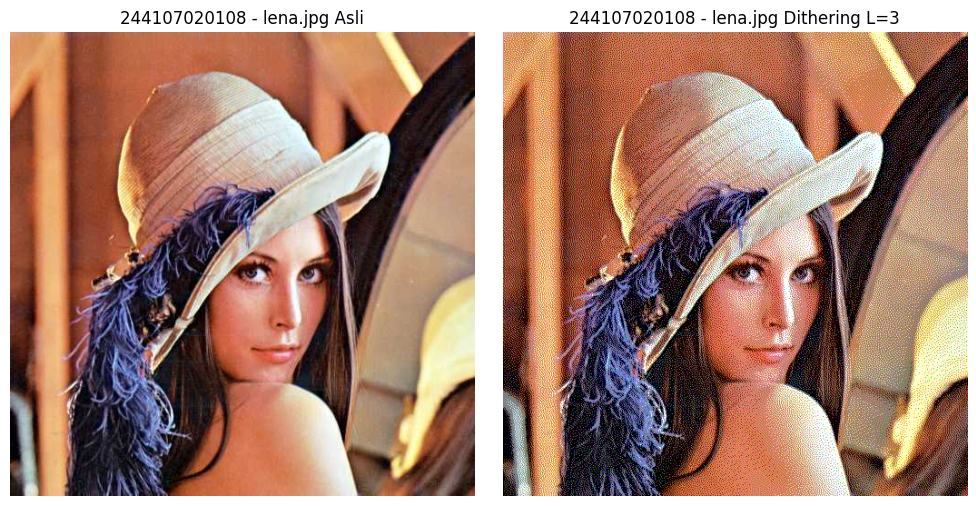

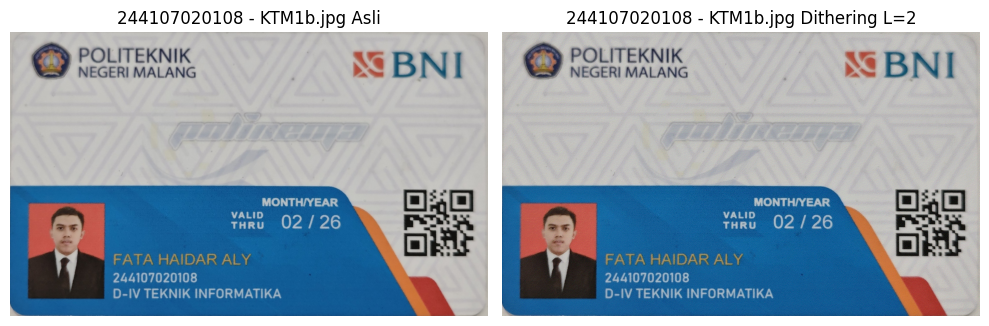

Level Lena : 3
Level KTM  : 2


In [52]:
# ==========================================
# TAHAP 1 - lena.jpg
# ==========================================
hasil_lena = dithering_warna(
    BASE + '/lena.jpg',
    'lena.jpg',
    3
)


# ==========================================
# TAHAP 2 - KTM1b.jpg
# ==========================================
hasil_ktm = dithering_warna(
    BASE + '/KTM1b.jpg',
    'KTM1b.jpg',
    PARAM['L']
)

print("Level Lena :", 3)
print("Level KTM  :", PARAM['L'])

**Jawab No 2 E-3**

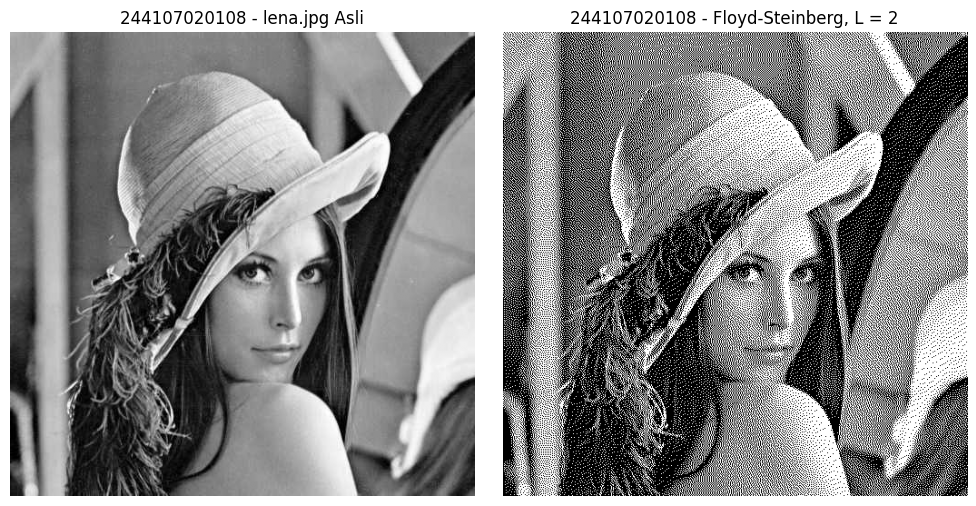

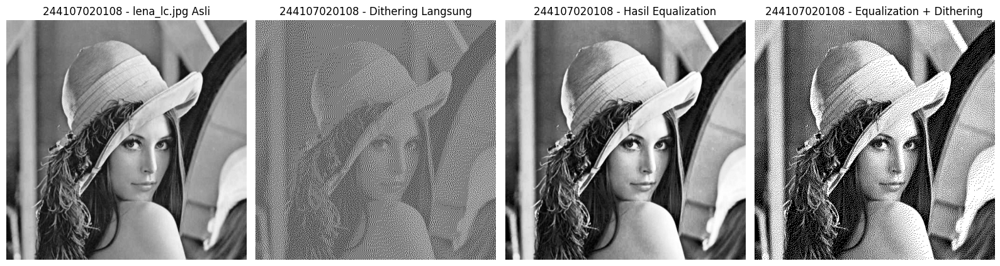

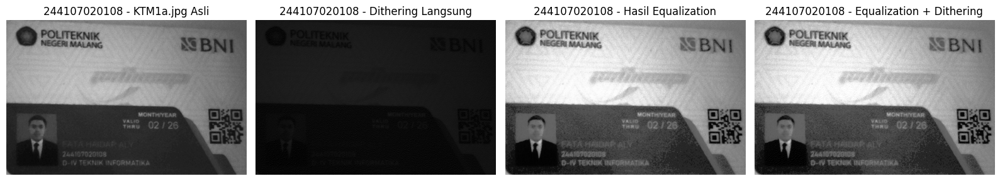

In [54]:
BASE = '/content/drive/MyDrive/PCVK'


# ==========================================
# FUNGSI FLOYD-STEINBERG
# ==========================================
def floyd_steinberg(gray, L=2):
    img = gray.astype(np.float32).copy()

    step = 255.0 / (L - 1)

    H, W = img.shape

    for y in range(H):
        for x in range(W):

            lama = img[y, x]

            # Kuantisasi ke level terdekat
            baru = np.round(lama / step) * step

            img[y, x] = baru

            # Hitung error
            error = lama - baru

            # Sebarkan error
            if x + 1 < W:
                img[y, x + 1] += error * 7 / 16

            if x > 0 and y + 1 < H:
                img[y + 1, x - 1] += error * 3 / 16

            if y + 1 < H:
                img[y + 1, x] += error * 5 / 16

            if x + 1 < W and y + 1 < H:
                img[y + 1, x + 1] += error * 1 / 16

    return np.clip(
        img,
        0,
        255
    ).astype(np.uint8)


# =========================================================
# BAGIAN 1
# LENA.JPG - FLOYD STEINBERG L = 2
# =========================================================
lena = cv.imread(
    BASE + '/lena.jpg',
    cv.IMREAD_GRAYSCALE
)

if lena is None:
    print('lena.jpg tidak ditemukan')

else:
    lena_dither = floyd_steinberg(
        lena,
        L=2
    )

    plt.figure(figsize=(10, 5))

    # Lena asli
    plt.subplot(1, 2, 1)
    plt.imshow(
        lena,
        cmap='gray'
    )
    plt.title(
        NIM + ' - lena.jpg Asli'
    )
    plt.axis('off')

    # Lena dithering
    plt.subplot(1, 2, 2)
    plt.imshow(
        lena_dither,
        cmap='gray'
    )
    plt.title(
        NIM + ' - Floyd-Steinberg, L = 2'
    )
    plt.axis('off')

    plt.tight_layout()
    plt.show()


# =========================================================
# FUNGSI:
# DITHERING LANGSUNG vs EQUALIZATION + DITHERING
# =========================================================
def he_dithering(path, nama):

    # Baca citra grayscale
    gray = cv.imread(
        path,
        cv.IMREAD_GRAYSCALE
    )

    if gray is None:
        print('Gambar tidak ditemukan:', path)
        return


    # =====================================
    # 1. DITHERING LANGSUNG
    # =====================================
    dither_langsung = floyd_steinberg(
        gray,
        L=2
    )


    # =====================================
    # 2. HISTOGRAM EQUALIZATION
    # =====================================
    equalized = cv.equalizeHist(gray)


    # =====================================
    # 3. EQUALIZATION + DITHERING
    # =====================================
    equalized_dither = floyd_steinberg(
        equalized,
        L=2
    )


    # =====================================
    # TAMPILKAN SEMUA DALAM 1 LAYOUT
    # =====================================
    plt.figure(figsize=(16, 5))


    # Citra asli
    plt.subplot(1, 4, 1)
    plt.imshow(
        gray,
        cmap='gray'
    )
    plt.title(
        NIM + ' - ' + nama + ' Asli'
    )
    plt.axis('off')


    # Dithering langsung
    plt.subplot(1, 4, 2)
    plt.imshow(
        dither_langsung,
        cmap='gray'
    )
    plt.title(
        NIM + ' - Dithering Langsung'
    )
    plt.axis('off')


    # Hasil equalization
    plt.subplot(1, 4, 3)
    plt.imshow(
        equalized,
        cmap='gray'
    )
    plt.title(
        NIM + ' - Hasil Equalization'
    )
    plt.axis('off')


    # Equalization kemudian dithering
    plt.subplot(1, 4, 4)
    plt.imshow(
        equalized_dither,
        cmap='gray'
    )
    plt.title(
        NIM + ' - Equalization + Dithering'
    )
    plt.axis('off')


    plt.tight_layout()
    plt.show()


# =========================================================
# BAGIAN 2
# TAHAP 1 - lena_lc.jpg
# =========================================================
he_dithering(
    BASE + '/lena_lc.jpg',
    'lena_lc.jpg'
)


# =========================================================
# TAHAP 2 - KTM1a.jpg
# =========================================================
he_dithering(
    BASE + '/KTM1a.jpg',
    'KTM1a.jpg'
)

**Penjelasan**

Dari hasil yang kamu tampilkan, dithering langsung tanpa equalization membuat citra KTM menjadi sangat gelap sehingga tulisan pada kartu hampir tidak terbaca.
Sedangkan pada urutan histogram equalization → dithering, kontras citra diperbaiki terlebih dahulu sehingga teks pada KTM tetap lebih jelas setelah proses dithering.
Jadi, urutan equalization lalu dithering menghasilkan teks KTM yang lebih terbaca dibanding dithering langsung.